## Características de la serie asignada
- **Nombre de la serie:** Indicador Mensual de Actividad Económica (Imacec), serie empalmada, volumen a precios del año anterior encadenado.
- **Frecuencia:** Mensual.
- **Unidad de medida:** Número índice (año base promedio 2018 = 100). No está expresada en porcentaje ni en unidades monetarias corrientes.
- **Fecha de inicio y fin:** La serie contiene observaciones continuas desde **enero de 2013** hasta **agosto de 2026**, totalizando 164 observaciones mensuales.

### Justificación del cálculo de variación en 12 meses
Para la tasa de desocupación, la variación anual se calculaba como una diferencia simple ($tasa_t - tasa_{t-12}$) porque dicha variable ya representa una proporción/porcentaje de la fuerza de trabajo, expresándose el cambio en puntos porcentuales (pp). En cambio, el Imacec es un índice de volumen (base promedio 2018 = 100). Por lo tanto, para medir la tasa de crecimiento interanual de la actividad económica se debe calcular la variación porcentual relativa respecto del nivel de hace 12 meses:
$$\text{var\_12m}_t = \left( \frac{\text{imacec}_t}{\text{imacec}_{t-12}} - 1 \right) \times 100$$

# 1. Paquetes

In [3]:
paquetes <- c("readr", "dplyr", "ggplot2", "scales", "tidyr", "lubridate", "stringr")
faltan <- paquetes[!paquetes %in% rownames(installed.packages())]
if (length(faltan) > 0) install.packages(faltan)

suppressPackageStartupMessages({
  library(readr); library(dplyr); library(ggplot2); library(scales)
  library(tidyr); library(lubridate); library(stringr)
})

# 2. Lectura y limpieza de datos

In [4]:
# Busca el archivo CSV en el directorio actual o /content
archivo <- list.files(c("/content", "."), pattern = "\\.csv$", full.names = TRUE)[1]
if (is.na(archivo)) stop("No encontré el archivo .csv. Súbelo desde el panel de archivos.")
cat("Leyendo:", archivo, "\n")

# Mapeo de meses en español para convertir 'ene.2013' a fecha válida
meses_dict <- c("ene"=1, "feb"=2, "mar"=3, "abr"=4, "may"=5, "jun"=6,
                "jul"=7, "ago"=8, "sep"=9, "oct"=10, "nov"=11, "dic"=12)

# Se saltan las dos primeras filas (título y fila vacía); encabezado en fila 3
raw <- read_delim(archivo, delim = ";", skip = 2, locale = locale(decimal_mark = ","), show_col_types = FALSE)

df <- raw |>
  select(periodo = 1, imacec = 2) |>
  filter(!is.na(periodo), !is.na(imacec)) |>
  mutate(
    periodo = str_trim(periodo),
    mes_str = str_extract(periodo, "^[a-z]{3}"),
    anio    = as.integer(str_extract(periodo, "\\d{4}$")),
    mes     = meses_dict[mes_str],
    fecha   = as.Date(paste(anio, mes, "01", sep = "-")),
    imacec  = as.numeric(imacec)
  ) |>
  filter(!is.na(fecha), !is.na(imacec)) |>
  arrange(fecha) |>
  mutate(
    media_12m = as.numeric(stats::filter(imacec, rep(1/12, 12), sides = 1)),           # Promedio móvil 12 meses
    var_12m   = (imacec / lag(imacec, 12) - 1) * 100                                  # Variación porcentual a 12 meses
  )

cat("Observaciones:", nrow(df), "\n")
summary(df$imacec)
tail(df)

Leyendo: ./CCNN2018_IMACEC_01_A(Cuadro).csv 


New names:
• `` -> `...3`
• `` -> `...4`
• `` -> `...5`
• `` -> `...6`
• `` -> `...7`
• `` -> `...8`
• `` -> `...9`
• `` -> `...10`
• `` -> `...11`


Observaciones: 164 


   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  82.29   93.58  100.24  100.97  107.84  129.20 

periodo,imacec,mes_str,anio,mes,fecha,media_12m,var_12m
<chr>,<dbl>,<chr>,<int>,<dbl>,<date>,<dbl>,<dbl>
mar.2026,120.37,mar,2026,3,2026-03-01,113.7442,0.09146848
abr.2026,114.36,abr,2026,4,2026-04-01,113.6408,-1.07266436
may.2026,112.11,may,2026,5,2026-05-01,113.5100,-1.38106967
jun.2026,110.60,jun,2026,6,2026-06-01,113.6917,2.01069913
jul.2026,106.97,jul,2026,7,2026-07-01,113.5575,-1.48277768
ago.2026,109.08,ago,2026,8,2026-08-01,113.4642,-1.01633394


# 3. Estilo común para los gráficos

In [5]:
meses_es  <- c("Ene","Feb","Mar","Abr","May","Jun","Jul","Ago","Sep","Oct","Nov","Dic")
etq_fecha <- function(x) paste(meses_es[as.integer(format(x, "%m"))], format(x, "%Y"))
num_es    <- function(x) number(x, accuracy = 0.1, decimal.mark = ",")

col_principal <- "#1F4E79"   # Azul institucional
col_acento    <- "#E07B39"   # Naranjo

tema <- theme_minimal(base_size = 13) +
  theme(
    plot.title          = element_text(face = "bold", size = 20, colour = "#1A1A1A"),
    plot.subtitle       = element_text(colour = "#555555", margin = margin(b = 12)),
    plot.caption        = element_text(colour = "#888888", size = 9, hjust = 0),
    plot.title.position = "plot", plot.caption.position = "plot",
    panel.grid.minor    = element_blank(),
    panel.grid.major.x  = element_blank(),
    panel.grid.major.y  = element_line(colour = "#E5E5E5"),
    legend.position     = "top", legend.justification = "left",
    plot.background     = element_rect(fill = "white", colour = NA),
    plot.margin         = margin(15, 20, 10, 15)
  )

fuente <- "Fuente: Banco Central de Chile, Cuentas Nacionales (base 2018=100). Serie CCNN2018_IMACEC_01_A (volumen a precios del año anterior encadenado, no desestacionalizada)."

#4. Gráfico 1: Evolución temporal del Imacec (Serie + Promedio móvil + Pandemia + Hitos)

Warning message in max(ids, na.rm = TRUE):
“no non-missing arguments to max; returning -Inf”


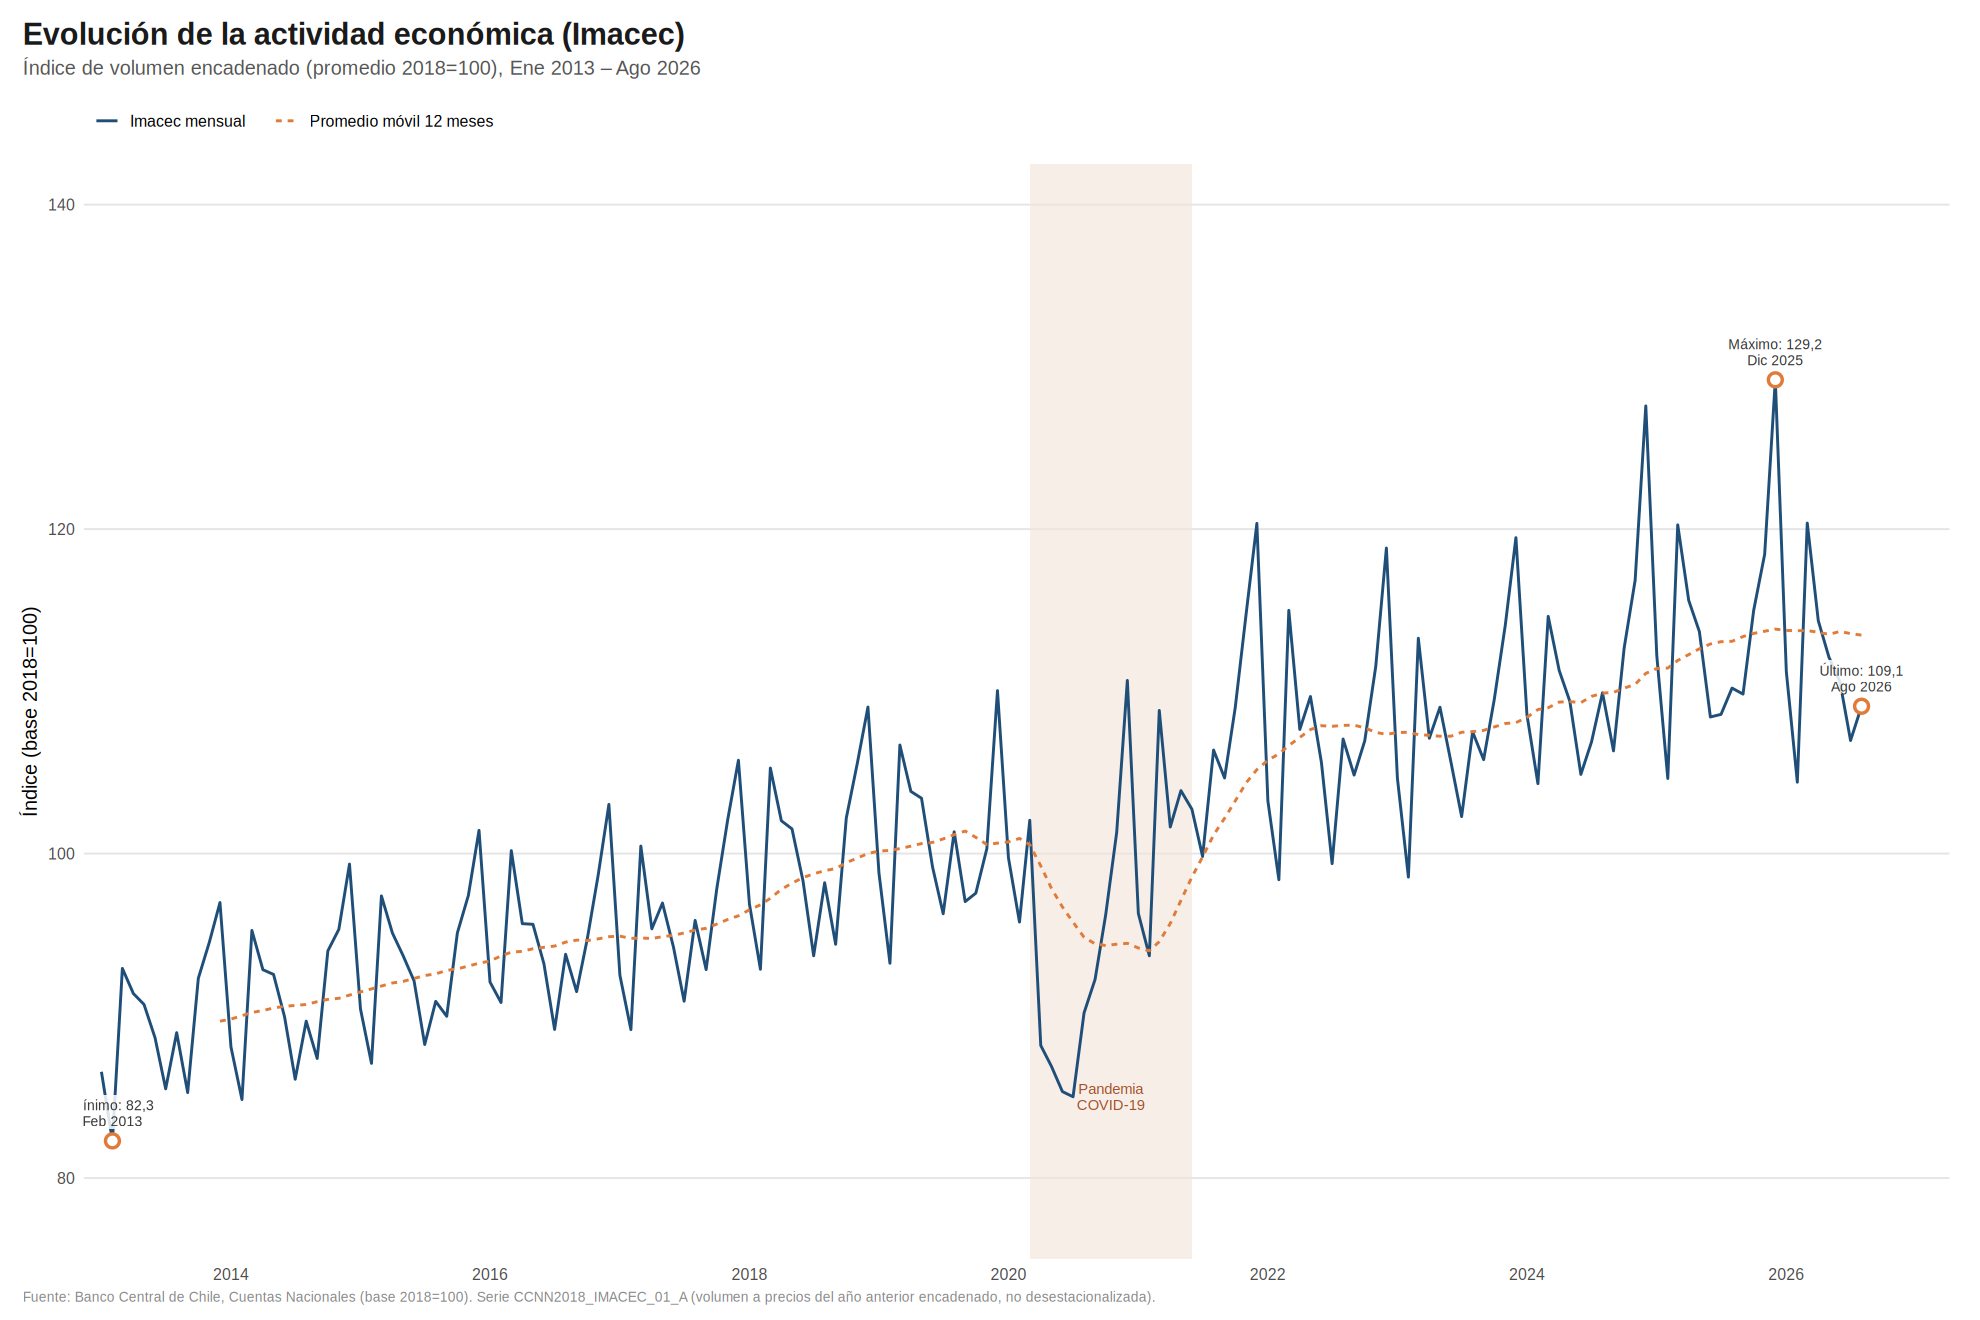

In [6]:
options(repr.plot.width = 18, repr.plot.height = 12, repr.plot.res = 110)

hitos <- bind_rows(
  df |> slice_max(imacec, n = 1) |> mutate(txt = paste0("Máximo: ", num_es(imacec), "\n", etq_fecha(fecha))),
  df |> slice_min(imacec, n = 1) |> mutate(txt = paste0("Mínimo: ", num_es(imacec), "\n", etq_fecha(fecha))),
  df |> slice_tail(n = 1)        |> mutate(txt = paste0("Último: ", num_es(imacec), "\n", etq_fecha(fecha)))
)

g1 <- ggplot(df, aes(fecha)) +
  annotate("rect", xmin = as.Date("2020-03-01"), xmax = as.Date("2021-06-01"),
           ymin = -Inf, ymax = Inf, fill = "#F3E3D8", alpha = .6) +
  annotate("text", x = as.Date("2020-10-15"), y = 85, label = "Pandemia\nCOVID-19",
           size = 3.4, colour = "#A0522D", lineheight = .9) +
  geom_area(aes(y = imacec), fill = col_principal, alpha = .07) +
  geom_line(aes(y = imacec, colour = "Imacec mensual"), linewidth = .9) +
  geom_line(aes(y = media_12m, colour = "Promedio móvil 12 meses"),
            linewidth = .9, linetype = "22", na.rm = TRUE) +
  geom_point(data = hitos, aes(y = imacec), size = 3.2, colour = col_acento,
             fill = "white", shape = 21, stroke = 1.6) +
  geom_label(data = hitos, aes(y = imacec, label = txt), size = 3.2, vjust = -0.35,
             linewidth = 0, fill = alpha("white", .85), colour = "#333333", lineheight = .95) +
  scale_colour_manual(NULL, values = c("Imacec mensual" = col_principal,
                                       "Promedio móvil 12 meses" = col_acento)) +
  scale_x_date(date_breaks = "2 years", date_labels = "%Y",
               expand = expansion(mult = c(.01, .05))) +
  scale_y_continuous(labels = label_number(accuracy = 1),
                     limits = c(75, max(df$imacec) + 12), expand = expansion(mult = c(0, .02))) +
  labs(title = "Evolución de la actividad económica (Imacec)",
       subtitle = paste0("Índice de volumen encadenado (promedio 2018=100), ",
                         etq_fecha(min(df$fecha)), " – ", etq_fecha(max(df$fecha))),
       x = NULL, y = "Índice (base 2018=100)", caption = fuente) +
  tema

g1

#5. Gráfico 2: Mapa de calor mensual y anual

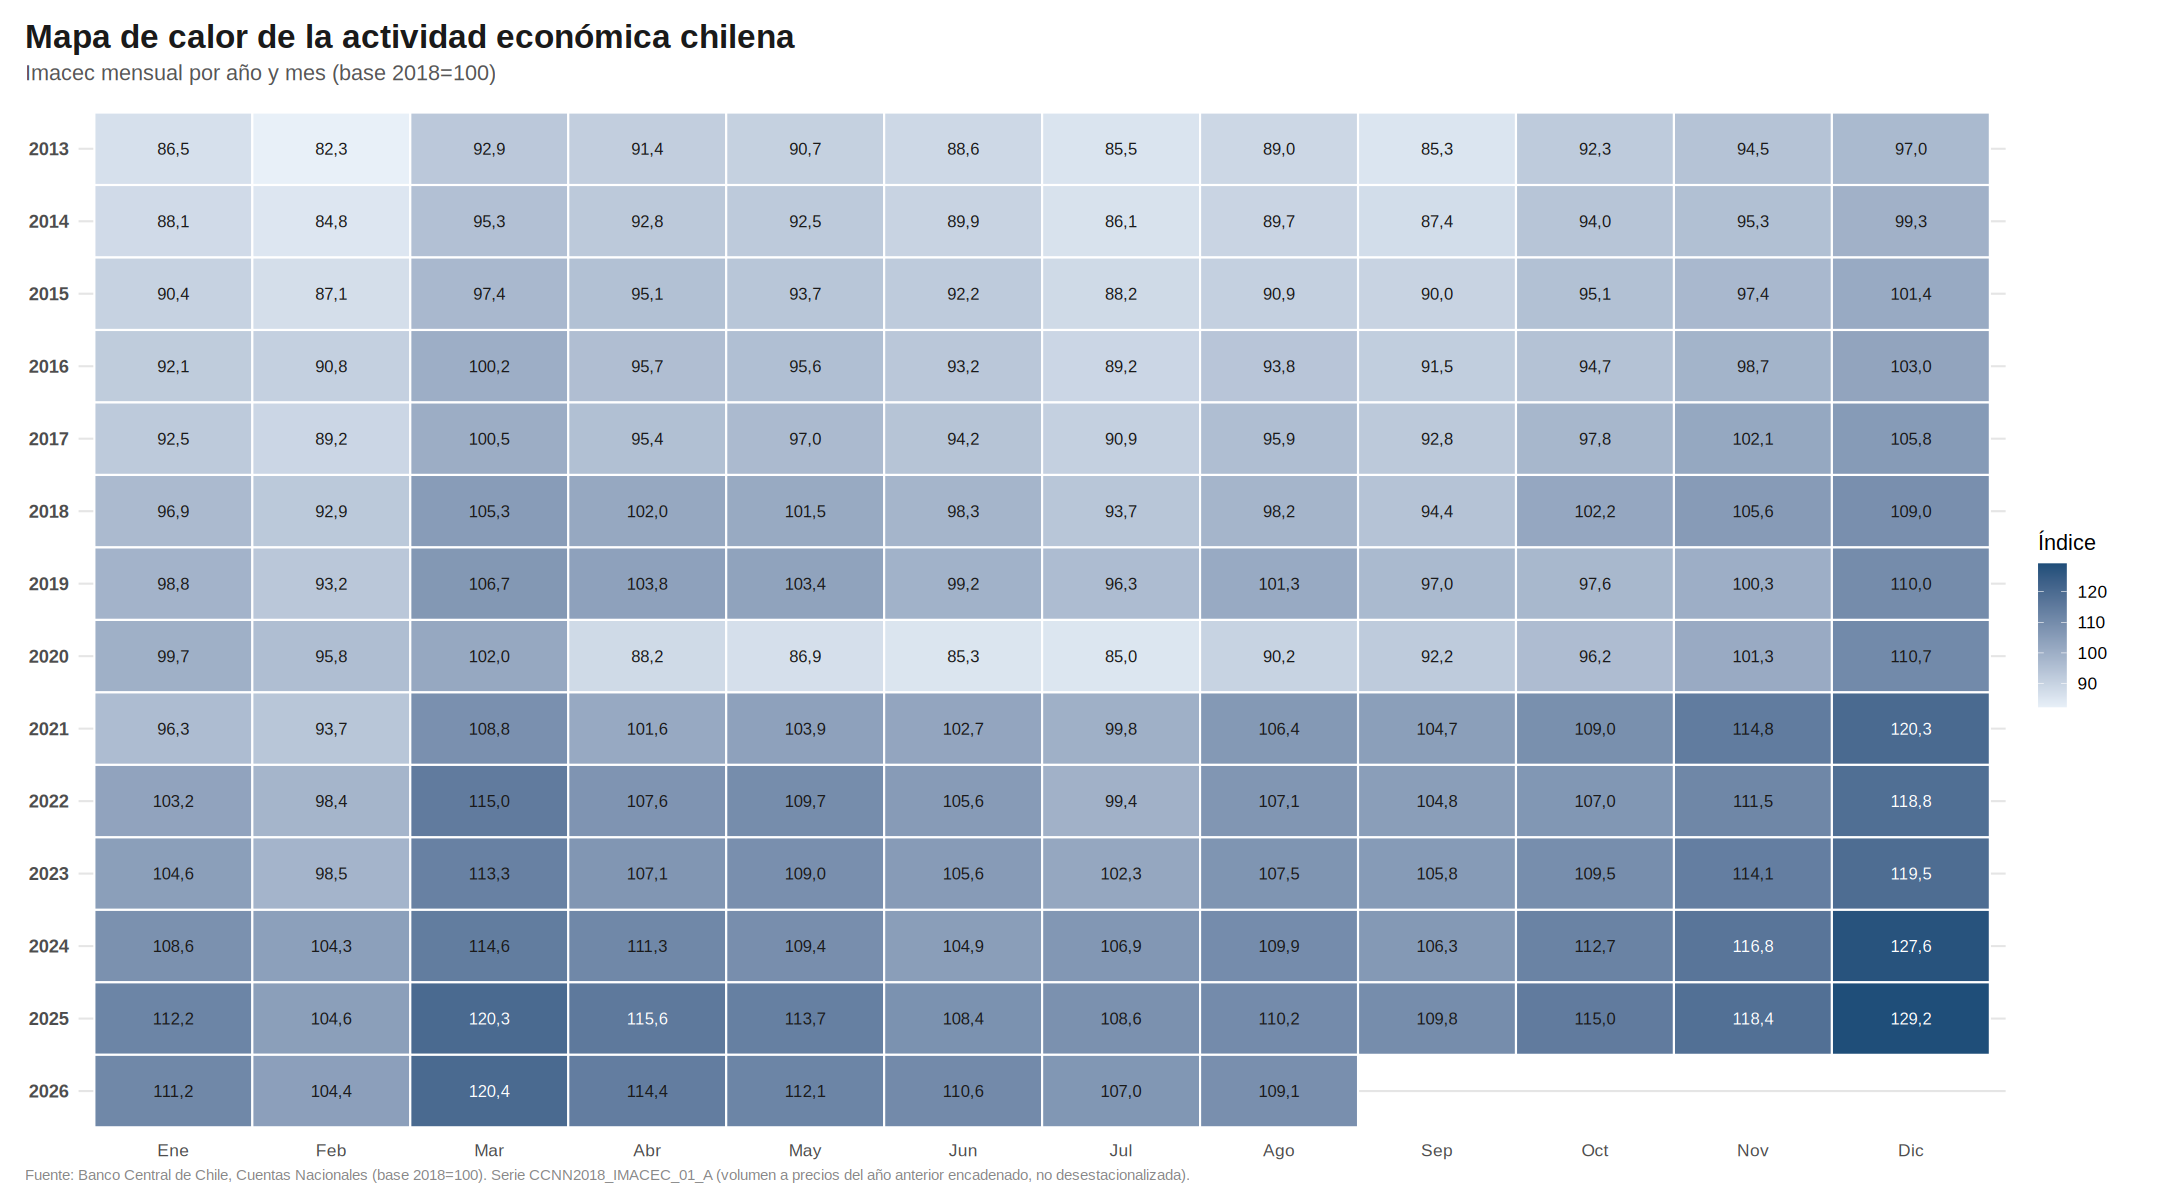

In [7]:
options(repr.plot.width = 18, repr.plot.height = 10, repr.plot.res = 120)

g2 <- ggplot(df, aes(factor(mes, levels = 1:12, labels = meses_es),
                     factor(anio, levels = rev(sort(unique(anio)))),
                     fill = imacec)) +
  geom_tile(colour = "white", linewidth = .6) +
  geom_text(aes(label = num_es(imacec), colour = imacec > 115), size = 3.5, show.legend = FALSE) +
  scale_colour_manual(values = c(`TRUE` = "white", `FALSE` = "#1A1A1A")) +
  scale_fill_gradient(low = "#E8F0F8", high = "#1F4E79", name = "Índice") +
  labs(title = "Mapa de calor de la actividad económica chilena",
       subtitle = "Imacec mensual por año y mes (base 2018=100)",
       x = NULL, y = NULL, caption = fuente) +
  tema +
  theme(
    panel.grid = element_blank(),
    legend.position = "right",
    axis.text.y = element_text(face = "bold", size = 11)
  )

g2

#6. Gráfico 3: Variación interanual en 12 meses (%)

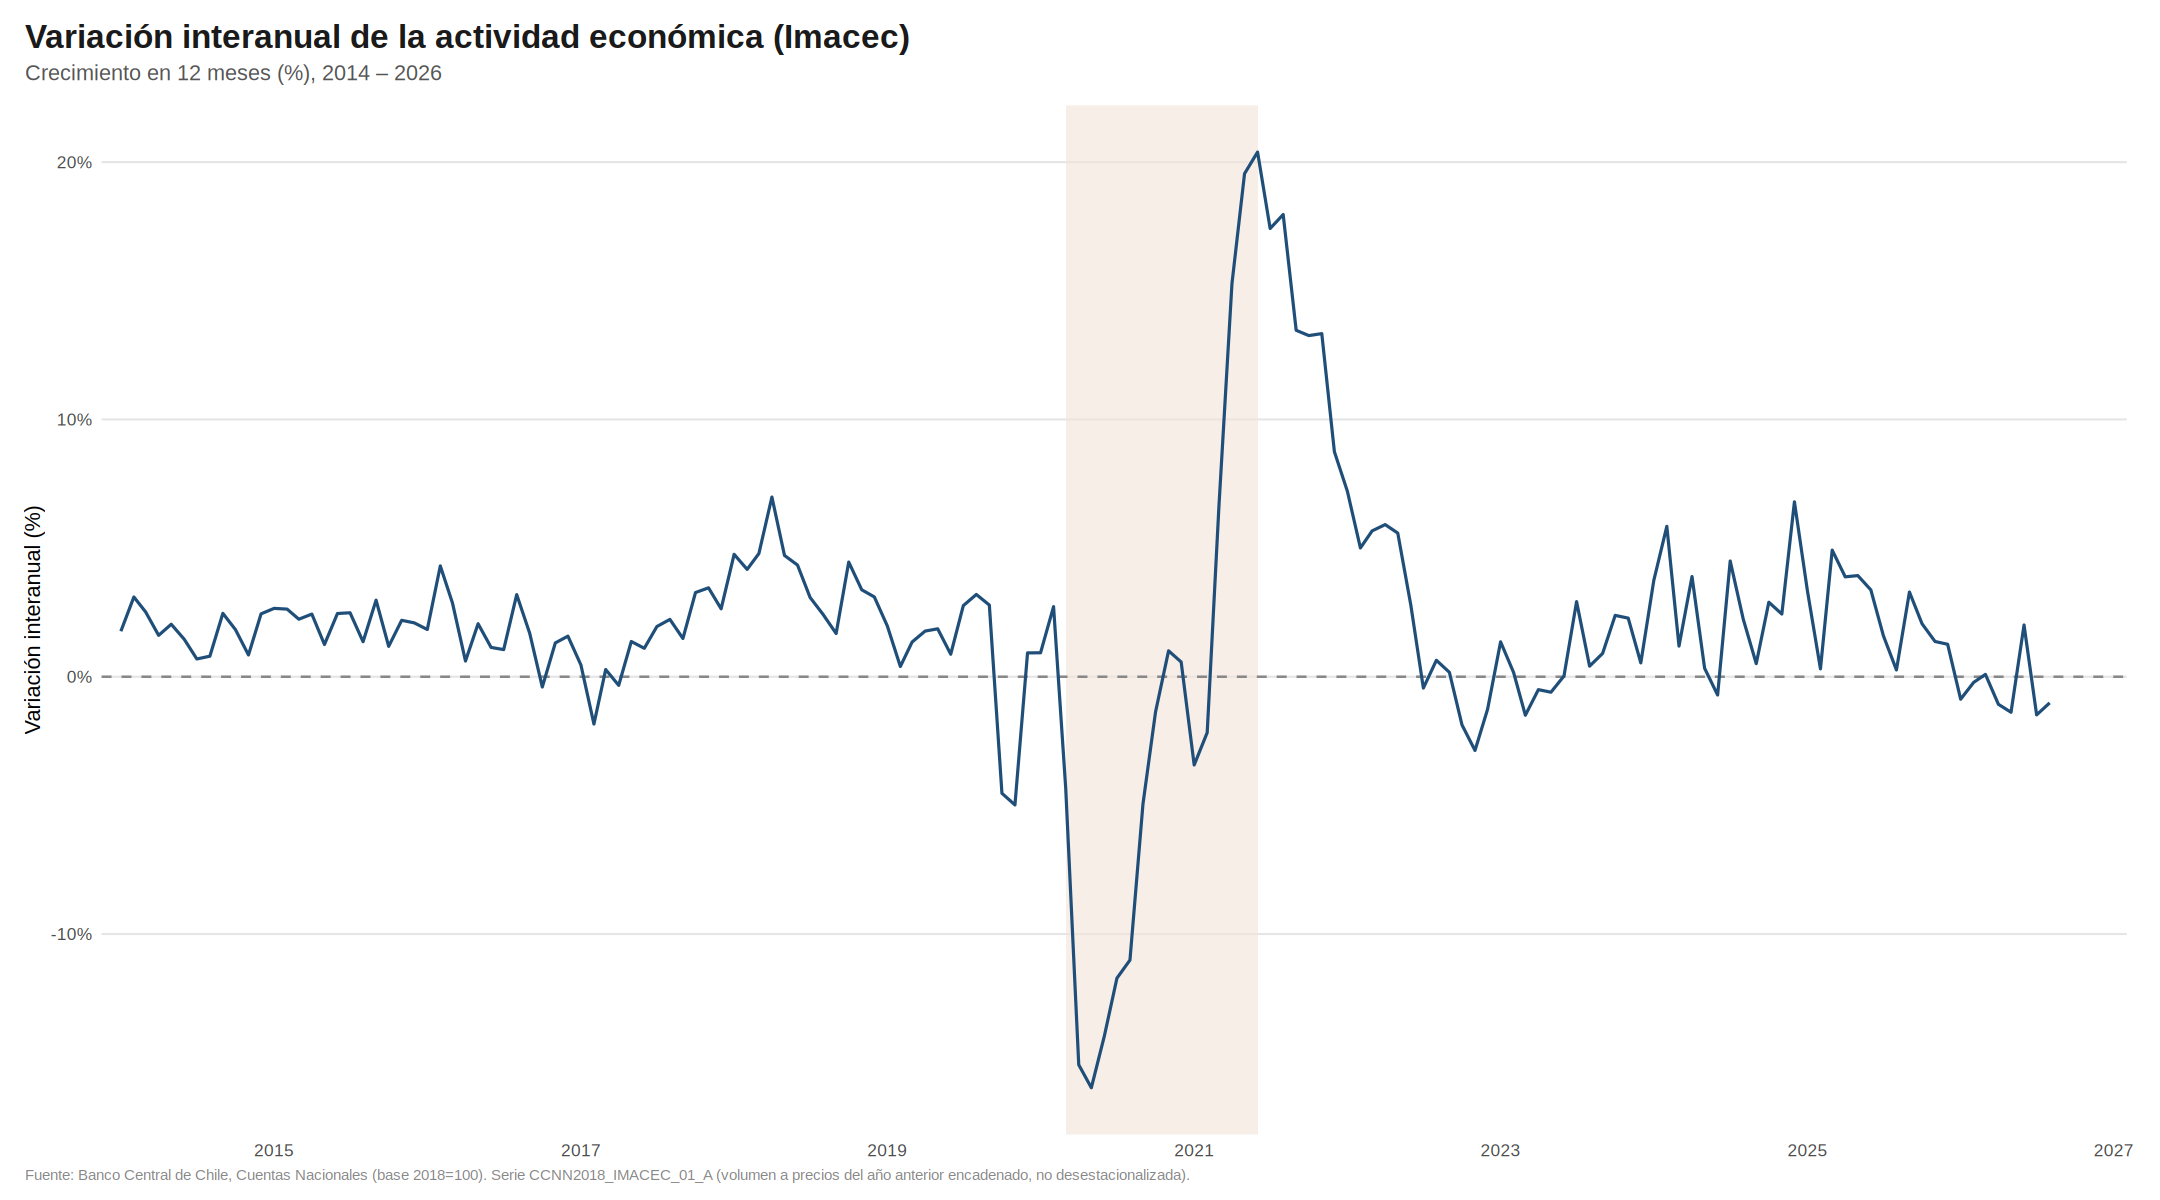

In [8]:
df_var <- df |> filter(!is.na(var_12m))

g3 <- ggplot(df_var, aes(x = fecha, y = var_12m)) +
  annotate("rect", xmin = as.Date("2020-03-01"), xmax = as.Date("2021-06-01"),
           ymin = -Inf, ymax = Inf, fill = "#F3E3D8", alpha = .6) +
  geom_hline(yintercept = 0, linetype = "dashed", colour = "#888888", linewidth = .7) +
  geom_line(colour = col_principal, linewidth = .9) +
  scale_x_date(date_breaks = "2 years", date_labels = "%Y",
               expand = expansion(mult = c(.01, .04))) +
  scale_y_continuous(labels = label_number(accuracy = 1, suffix = "%")) +
  labs(title = "Variación interanual de la actividad económica (Imacec)",
       subtitle = "Crecimiento en 12 meses (%), 2014 – 2026",
       x = NULL, y = "Variación interanual (%)", caption = fuente) +
  tema

g3

## Interpretación económica de los resultados

El análisis del Indicador Mensual de Actividad Económica (Imacec) entre enero de 2013 y agosto de 2026 permite caracterizar la trayectoria tendencial, la marcada estacionalidad y las perturbaciones macroeconómicas que han afectado a la economía chilena durante la última década.

El valor más reciente registrado en la serie corresponde a agosto de 2026, con un índice de 109,08 puntos. Este registro se sitúa por sobre el promedio histórico de todo el período analizado (101,0 puntos), reflejando la expansión acumulada del producto potencial a lo largo de los años. No obstante, al compararlo con la media móvil de 12 meses (113,5 puntos), el nivel se encuentra por debajo de la tendencia reciente, lo que da cuenta de un dinamismo moderado hacia mediados de 2026.

Los valores extremos de la serie ilustran eventos económicos clave. El mínimo histórico se registró en febrero de 2013 (82,3 puntos), coincidente con el inicio de la muestra y la menor actividad que siempre tiene febrero por el receso de vacaciones y los menores días laborales. Por su parte, la contracción más severa en términos de variación interanual ocurrió en mayo de 2020 (-16,0%), producto de la irrupción de la pandemia de COVID-19 y las estrictas medidas de confinamiento sanitario que paralizaron sectores intensivos en presencialidad. En contraste, el máximo absoluto del índice se alcanzó en diciembre de 2025 (129,2 puntos), mientras que el mayor crecimiento interanual tuvo lugar en junio de 2021 (+20,4%), impulsado por la reapertura económica, las transferencias fiscales universales y los retiros de fondos previsionales, junto con una baja base de comparación.

El mapa de calor evidencia un marcado patrón estacional intraanual. Sistemáticamente, febrero y julio constituyen los meses de menor actividad económica relativa, afectados por las vacaciones y el menor número de días hábiles. En contraposición, marzo y diciembre muestran de manera recurrente las tonalidades más intensas del indicador, debido al reinicio de faenas, la actividad escolar y el dinamismo extraordinario del comercio durante las festividades de fin de año. Finalmente, la variación en 12 meses a agosto de 2026 se sitúa en terreno levemente contractivo (-1,0%), reflejando una fase de normalización y desaceleración del ciclo tras los picos del año precedente.